In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de scikit-learn
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


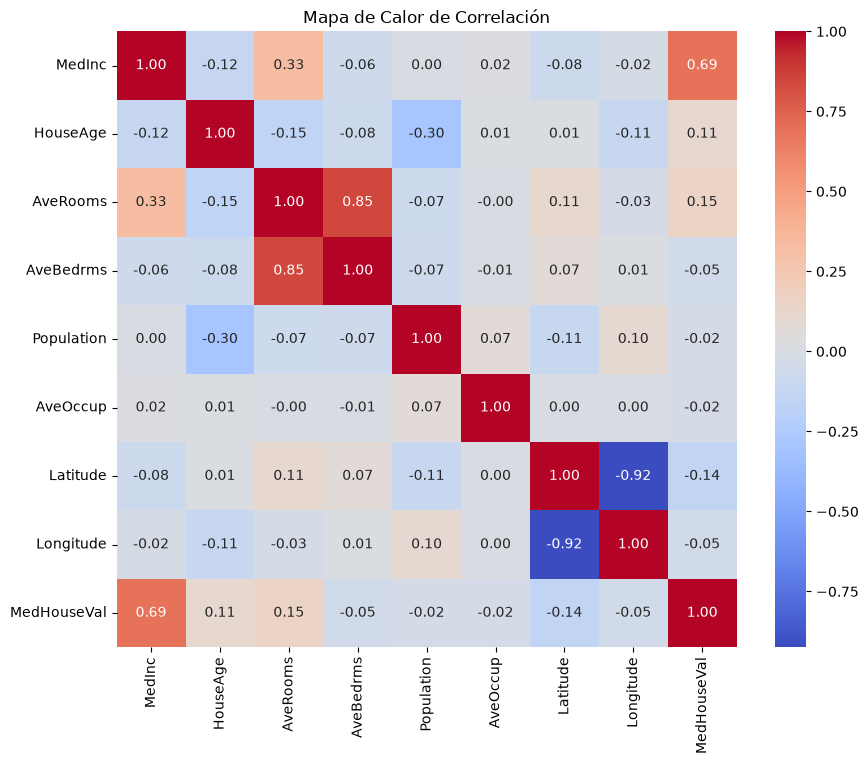

In [3]:
# 1. Cargar el dataset oficial de California Housing
data = fetch_california_housing(as_frame=True)
df = data.frame

# 2. Imputación de valores faltantes (sustituye valores nulos con la mediana)
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# 3. Dibujar el mapa de calor de correlación (Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(df_imputed.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Mapa de Calor de Correlación")
plt.show()

In [5]:
# 1. Ingeniería de características
df_imputed['Rooms_per_Household'] = df_imputed['AveRooms'] / df_imputed['AveOccup']

# 2. Codificación de variables categóricas (One-Hot Encoding por si existen atributos cualitativos)
df_imputed = pd.get_dummies(df_imputed, drop_first=True)

# 3. Separación de características (X) y variable objetivo (y)
X = df_imputed.drop(columns=['MedHouseVal'])
y = df_imputed['MedHouseVal']

# 4. División en Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Estandarización de variables continuas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# A. Modelo Mínimos Cuadrados Ordinarios (OLS)
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

# B. Modelo Ridge con ajuste de alfa usando GridSearchCV
param_grid_ridge = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
ridge_cv = GridSearchCV(Ridge(), param_grid_ridge, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train)

# C. Modelo Lasso con ajuste de alfa usando GridSearchCV
param_grid_lasso = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}
lasso_cv = GridSearchCV(Lasso(), param_grid_lasso, cv=5, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Lasso()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hig

In [8]:
# Función para calcular métricas
def calcular_metricas(modelo, X, y):
    preds = modelo.predict(X)
    rmse = np.sqrt(mean_squared_error(y, preds))
    mae = mean_absolute_error(y, preds)
    r2 = r2_score(y, preds)
    return rmse, mae, r2, preds

# Obtención de métricas
rmse_ols, mae_ols, r2_ols, preds_ols = calcular_metricas(ols, X_test_scaled, y_test)
rmse_ridge, mae_ridge, r2_ridge, preds_ridge = calcular_metricas(ridge_cv.best_estimator_, X_test_scaled, y_test)
rmse_lasso, mae_lasso, r2_lasso, preds_lasso = calcular_metricas(lasso_cv.best_estimator_, X_test_scaled, y_test)

# Generar tabla comparativa exigida
tabla_metricas = pd.DataFrame({
    'Modelo': ['OLS (Mínimos Cuadrados)', f'Ridge (alpha={ridge_cv.best_params_["alpha"]})', f'Lasso (alpha={lasso_cv.best_params_["alpha"]})'],
    'RMSE': [rmse_ols, rmse_ridge, rmse_lasso],
    'MAE': [mae_ols, mae_ridge, mae_lasso],
    'R² Score': [r2_ols, r2_ridge, r2_lasso]
})

print("--- TABLA COMPARATIVA DE MÉTRICAS ---")
display(tabla_metricas)




--- TABLA COMPARATIVA DE MÉTRICAS ---


,Modelo,RMSE,MAE,R² Score
0,OLS (Mínimos Cuadrados),0.687308,0.495886,0.639508
1,Ridge (alpha=10.0),0.687315,0.495908,0.639500
2,Lasso (alpha=0.001),0.687143,0.496071,0.639681


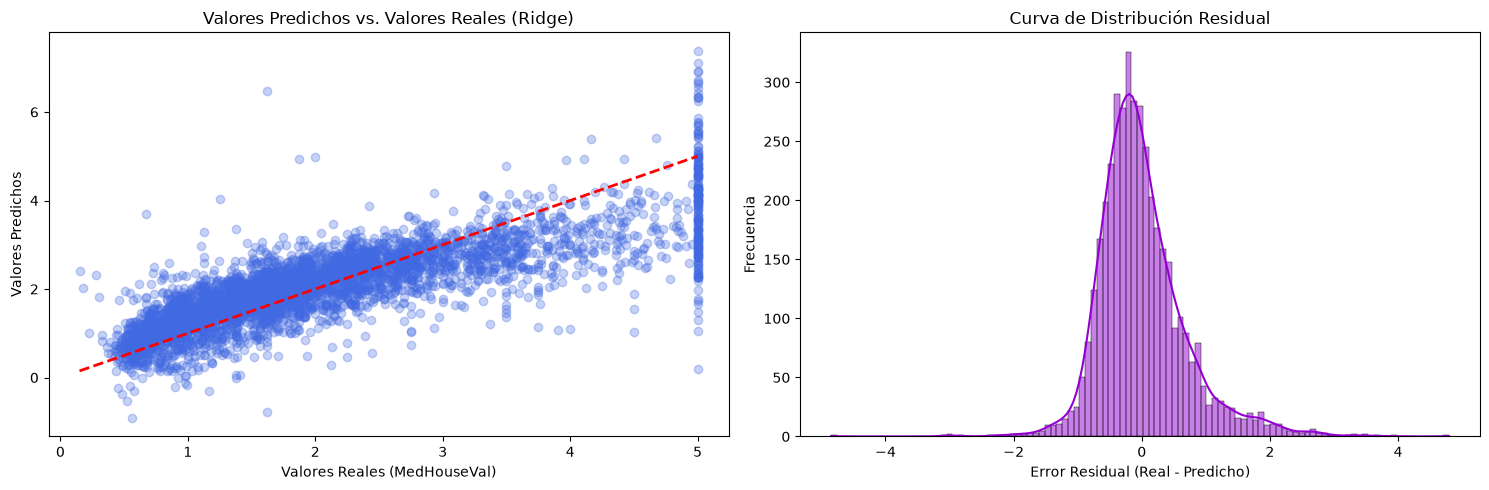

In [9]:
# Configuración del lienzo para 2 gráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Predichos vs Reales
axes[0].scatter(y_test, preds_ridge, alpha=0.3, color='royalblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel("Valores Reales (MedHouseVal)")
axes[0].set_ylabel("Valores Predichos")
axes[0].set_title("Valores Predichos vs. Valores Reales (Ridge)")

# Gráfico 2: Curva de Distribución Residual
errores_residuales = y_test - preds_ridge
sns.histplot(errores_residuales, kde=True, ax=axes[1], color='darkviolet')
axes[1].set_xlabel("Error Residual (Real - Predicho)")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Curva de Distribución Residual")

plt.tight_layout()
plt.show()